# Demonstration of Phase estimation

This is a demonstration of Phase estimation

# Boiletplate

In [1]:
# Boilerplate to run 
## Qiskit stuff
from qiskit import QuantumCircuit 
from qiskit.circuit.library import QFTGate, PhaseEstimation, PhaseGate, UnitaryGate
from qiskit.visualization import plot_histogram, plot_bloch_multivector
from qiskit_ibm_runtime import SamplerV2 as Sampler
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

# Import a local fake backend instead of using QiskitRuntimeService
from qiskit_ibm_runtime.fake_provider import FakeManilaV2
from qiskit.primitives import BackendSamplerV2

# Load the Aer simulator and generate a noise model locally
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel

# Instantiate the fake backend (no cloud connection required)
backend = FakeManilaV2()

# Generate the noise model based on the local fake backend
noise_model = NoiseModel.from_backend(backend)

# Define a simulator using Aer, and use it in Sampler.
backend_sim = AerSimulator(noise_model=noise_model)
sampler_sim = BackendSamplerV2(backend=backend_sim)

## Other stuff for image generation
import numpy as np
from IPython.display import display
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt 
import matplotlib.patches as patches

# This style sheet is in use.
plt.style.use('../intro_to_qml_figure_style.mpltstyle') 
import warnings 
warnings.filterwarnings( # Filter out the specific tight_layout warning generated by Jupyter/Matplotlib 3D plots
    "ignore", 
    category=UserWarning, 
    message="This figure includes Axes that are not compatible with tight_layout"
)
figure_directory = '../Figures/Ch2_Quantum_Algorithms_Figures/'

def plot_histogram_reversed(counts, title=None, font_size=10):
    """Helper to reverse bitstrings (q_0 -> q_n) and apply custom font sizing."""
    # Reverse key bitstrings
    rev_counts = {k[::-1]: v for k, v in counts.items()}
    
    # Temporarily set styling context for this figure only
    with plt.rc_context({
        'font.size': font_size,
        'axes.titlesize': font_size + 2,
        'axes.labelsize': font_size,
        'xtick.labelsize': font_size - 1,
        'ytick.labelsize': font_size - 1
    }):
        return plot_histogram(rev_counts, title=title)


# Define style dictionary to increase gate font size
qiskit_style = {
    'fontsize': 14,        # Default is 13; increase this value for larger gate text
    'subfontsize': 15      # Default is 8; Controls subscript text size (e.g., control indices or parameters)
}


# Phase estimation with $\theta=1/3$

## Defining the Unitary Gate

For our gate, let's choose a phase gate with a rotation of $2 \pi \theta$, where $\theta=1/3$ around the 'z' axis

This has an eigenvalue $\ket{1}$ where $U \ket{1} = e^{2 \pi \theta} \ket{1}$

In [2]:
phase =  np.pi * (2/3)
unitary_p_gate = PhaseGate(phase)

Let's demonstrate this phase gate for $\ket{+}$ state

/var/folders/9k/jzqcwwz92p35vtq6ypw0mkh40000gn/T/ipykernel_60230/2260224536.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/var/folders/9k/jzqcwwz92p35vtq6ypw0mkh40000gn/T/ipykernel_60230/2260224536.py:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


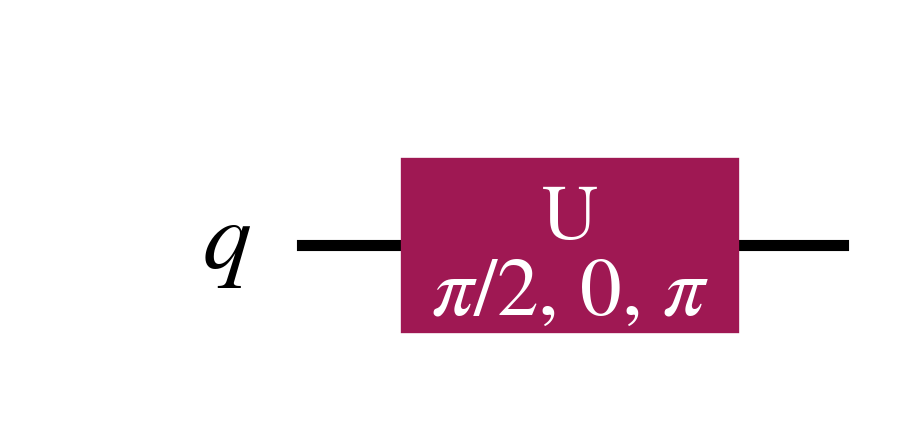

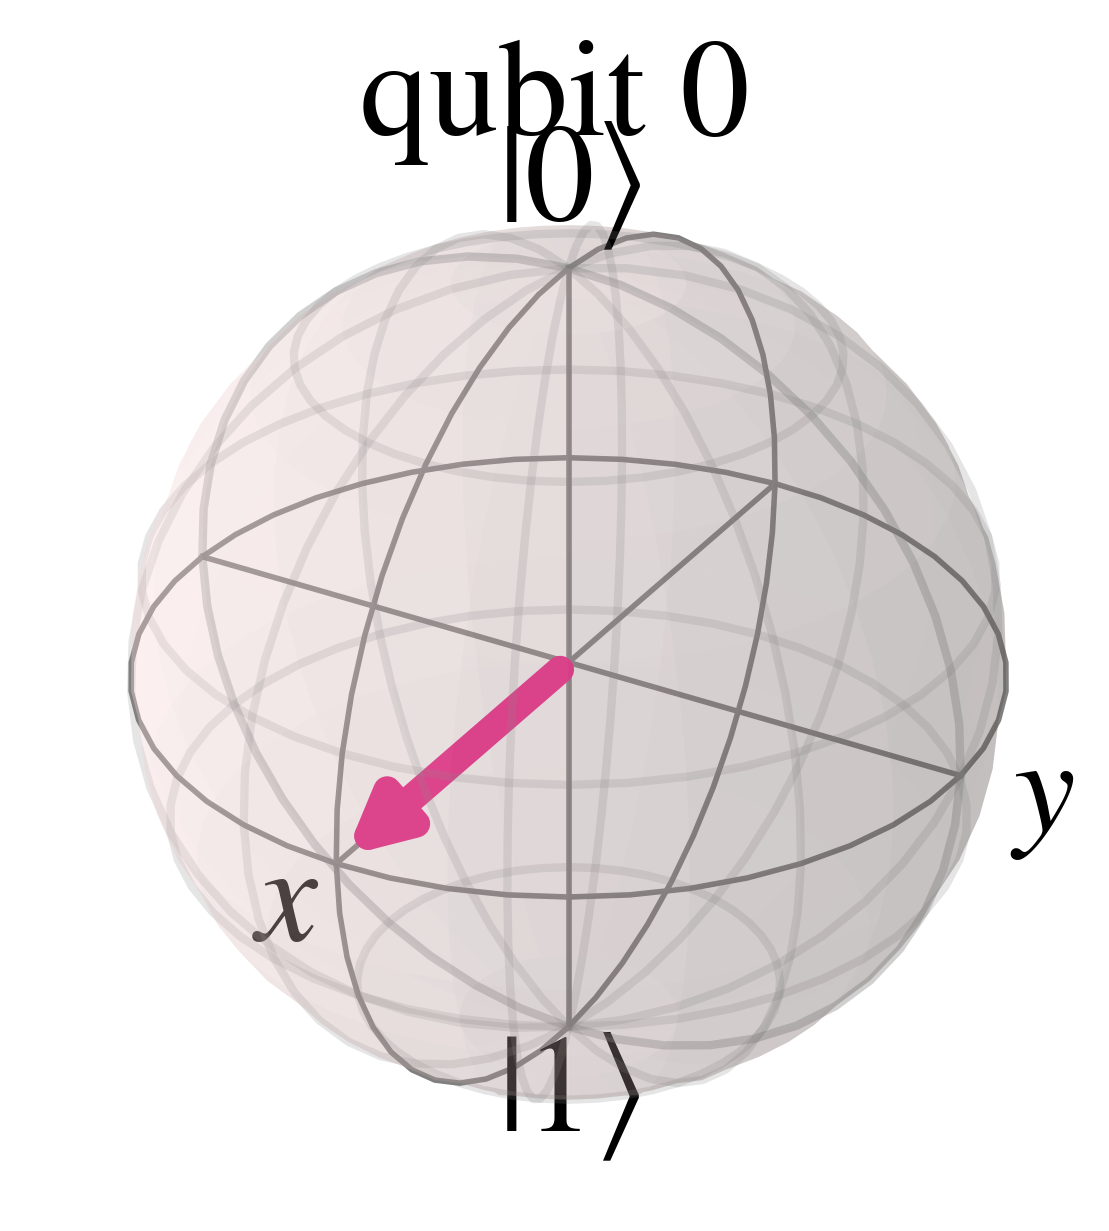

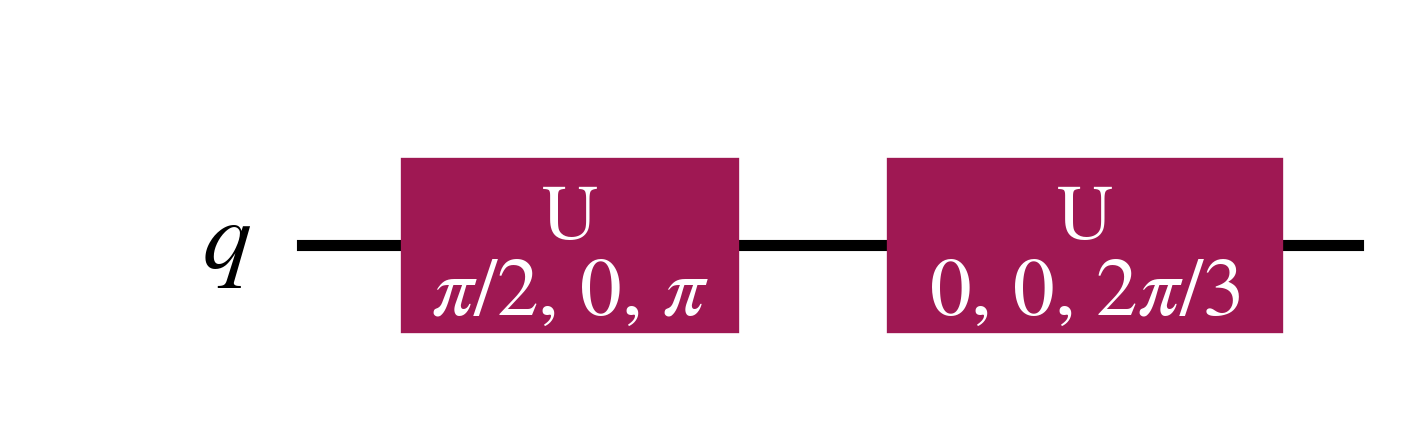

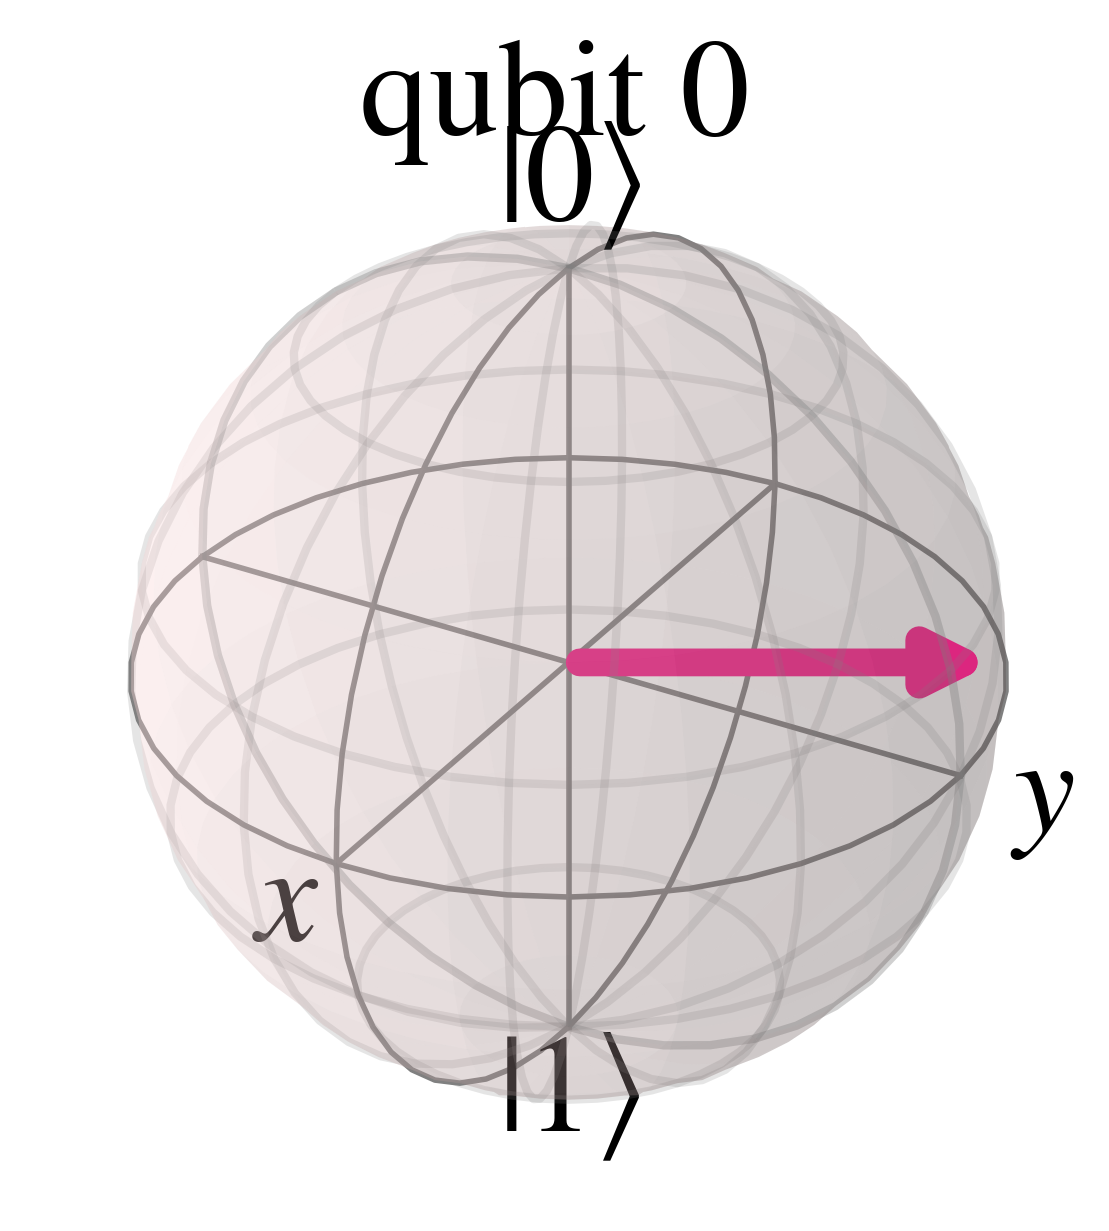

In [3]:
qc = QuantumCircuit(1)
qc.h(0)
fig = qc.decompose().draw("mpl", style=qiskit_style)

qc.save_statevector()
statevector = backend_sim.run(qc).result().get_statevector()
fig = plot_bloch_multivector(statevector)
fig.show()

qc = QuantumCircuit(1)
qc.h(0)
qc.append(unitary_p_gate, [0])
fig = qc.decompose().draw("mpl", style=qiskit_style)

qc.save_statevector()
statevector = backend_sim.run(qc).result().get_statevector()
fig = plot_bloch_multivector(statevector)
fig.show()

## 3 measurement qubit case

Probability of achieving 011 for 3 measurement qubits is 69.24%


/var/folders/9k/jzqcwwz92p35vtq6ypw0mkh40000gn/T/ipykernel_60230/2208637883.py:4: DeprecationWarning: The class ``qiskit.circuit.library.phase_estimation.PhaseEstimation`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use qiskit.circuit.library.phase_estimation instead.
  qpe.compose(PhaseEstimation(measurement_qubits, unitary_p_gate), inplace=True)
/var/folders/9k/jzqcwwz92p35vtq6ypw0mkh40000gn/T/ipykernel_60230/2208637883.py:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


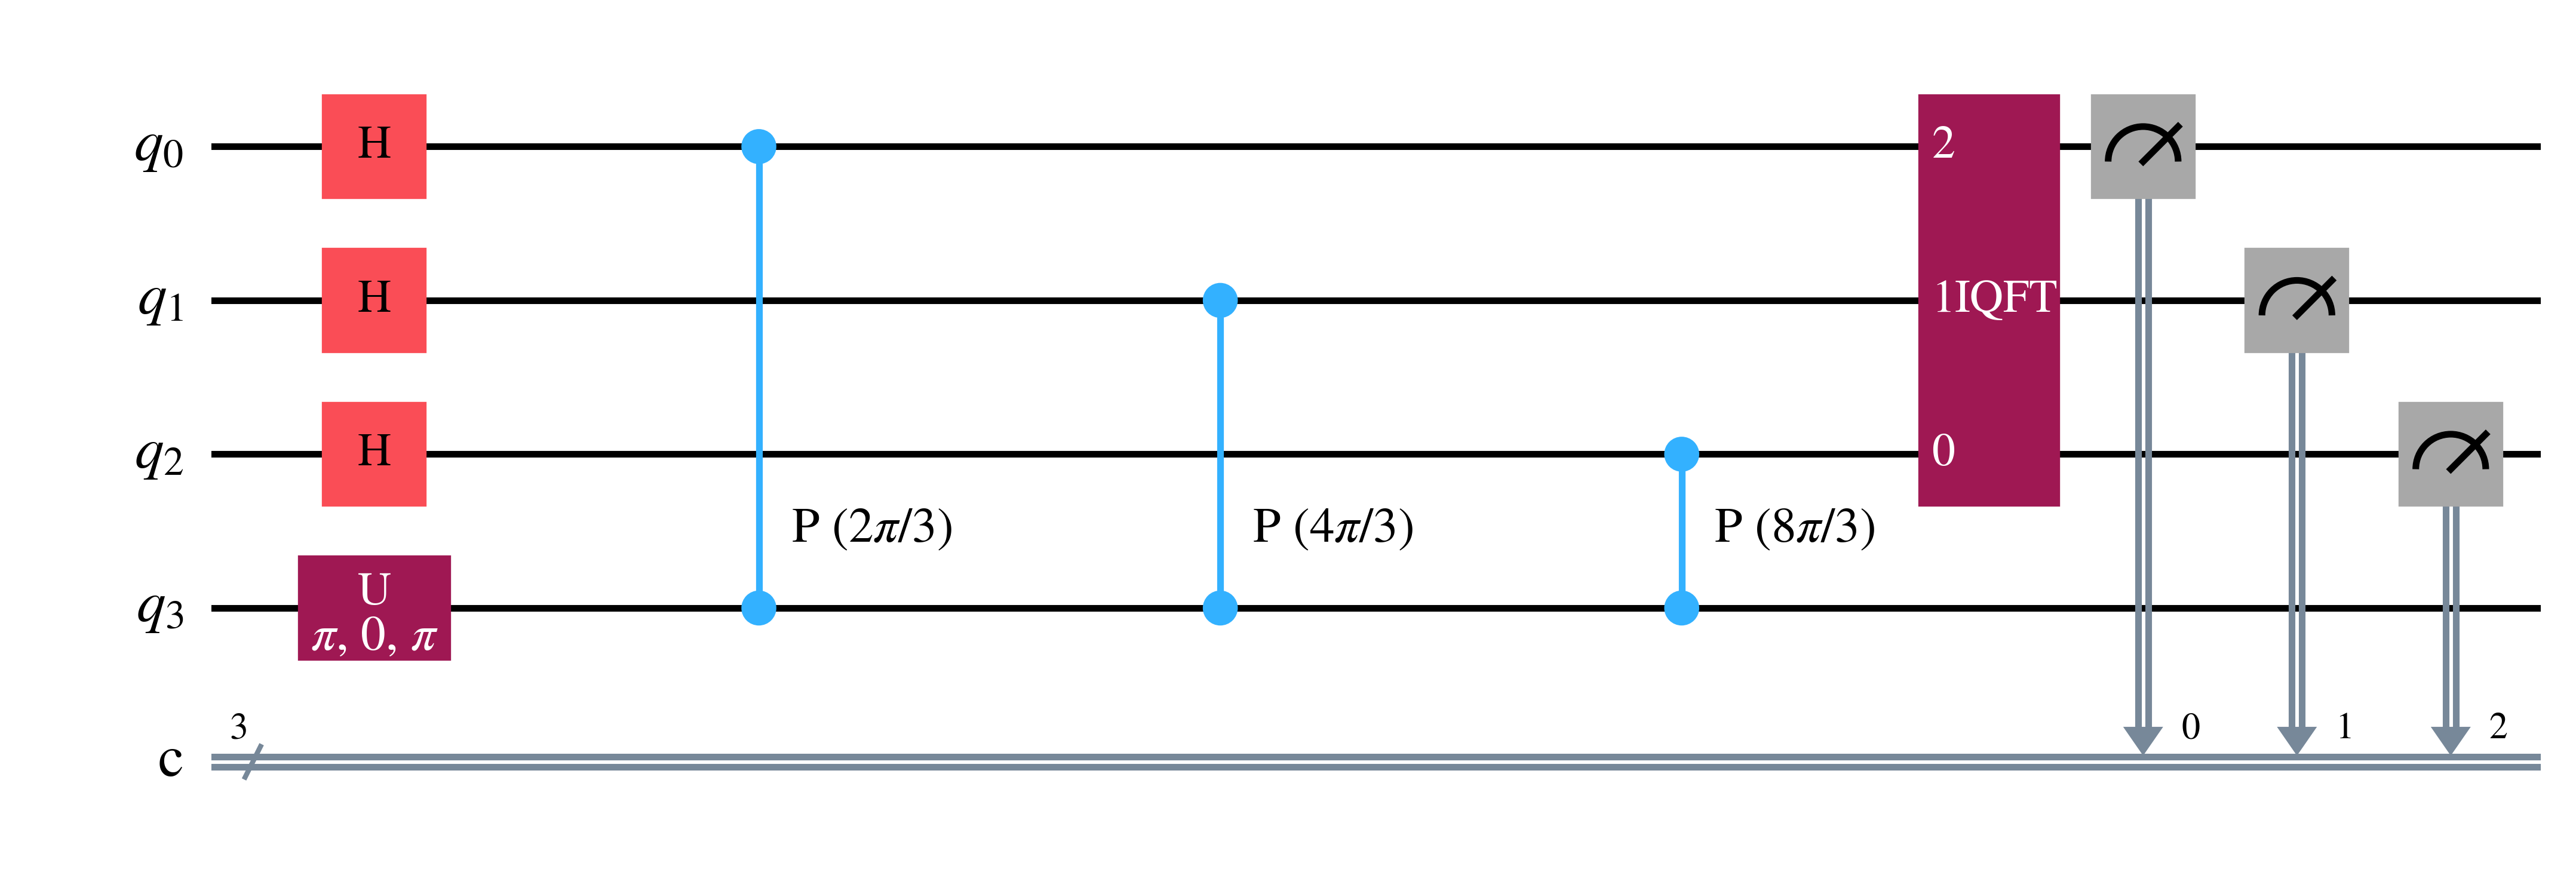

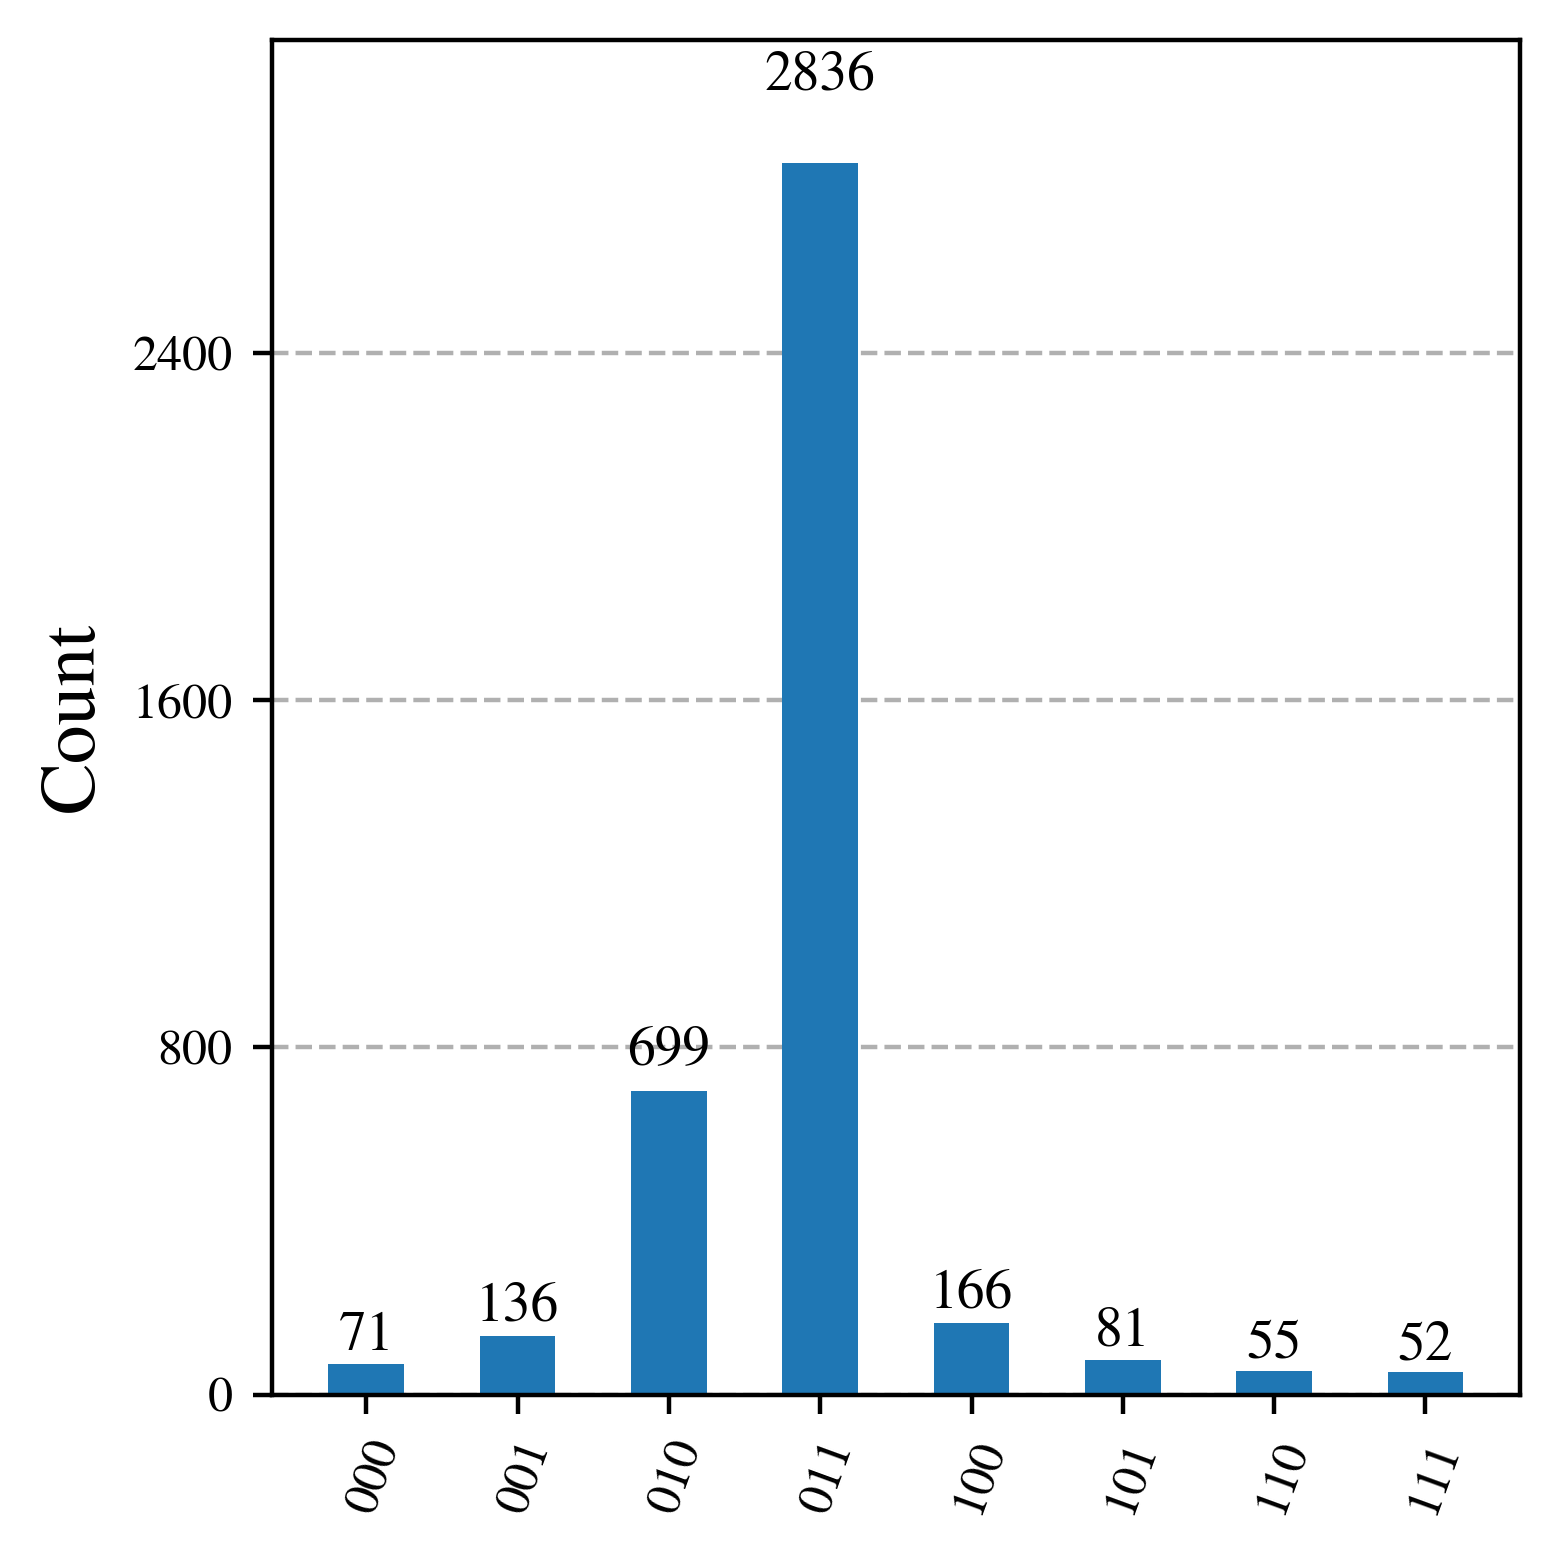

In [4]:
measurement_qubits = 3
qpe = QuantumCircuit(measurement_qubits+1, measurement_qubits)
qpe.x(measurement_qubits)
qpe.compose(PhaseEstimation(measurement_qubits, unitary_p_gate), inplace=True)
for n in range(0,measurement_qubits):
    qpe.measure(n, n)
fig = qpe.decompose().draw("mpl", style=qiskit_style)

aer_sim = AerSimulator()
shots = 4096

pm = generate_preset_pass_manager(backend=aer_sim, optimization_level=1)
t_qpe = pm.run(qpe)

sampler = Sampler(mode=aer_sim)
job = sampler.run([t_qpe], shots=shots)
result = job.result()
answer = result[0].data.c.get_counts()

fig=plot_histogram_reversed(answer)
fig.show()

probability_3_qubits = answer['110']/shots * 100
output_string = f"Probability of achieving 011 for {measurement_qubits} measurement qubits is {probability_3_qubits:.2f}%"
print(output_string)


## 5 measurement qubit case

The most common result above is 011, corresponding to $0.011 = \frac{0}{2^2} + \frac{1}{2^2}+ \frac{1}{2^3} = 0 + 0.25 + 0.125 = 0.375$
The second common result above is 011, corresponding to $0.010 = \frac{0}{2^2} + \frac{1}{2^2}+ \frac{0}{2^3} = 0 + 0.25 + 0 = 0.25$
These together bound the expected value of $\frac{1}{3} = 0.333\ldots = 0.\overline{3}$.

Now, let's increase the precision by increasing the number of measurement qubits and see what happens

/var/folders/9k/jzqcwwz92p35vtq6ypw0mkh40000gn/T/ipykernel_60230/2627228808.py:4: DeprecationWarning: The class ``qiskit.circuit.library.phase_estimation.PhaseEstimation`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use qiskit.circuit.library.phase_estimation instead.
  qpe.compose(PhaseEstimation(measurement_qubits, unitary_p_gate), inplace=True)
/var/folders/9k/jzqcwwz92p35vtq6ypw0mkh40000gn/T/ipykernel_60230/2627228808.py:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


Probability of achieving 011 (after rounding) for 5 measurement qubits is 91.28%


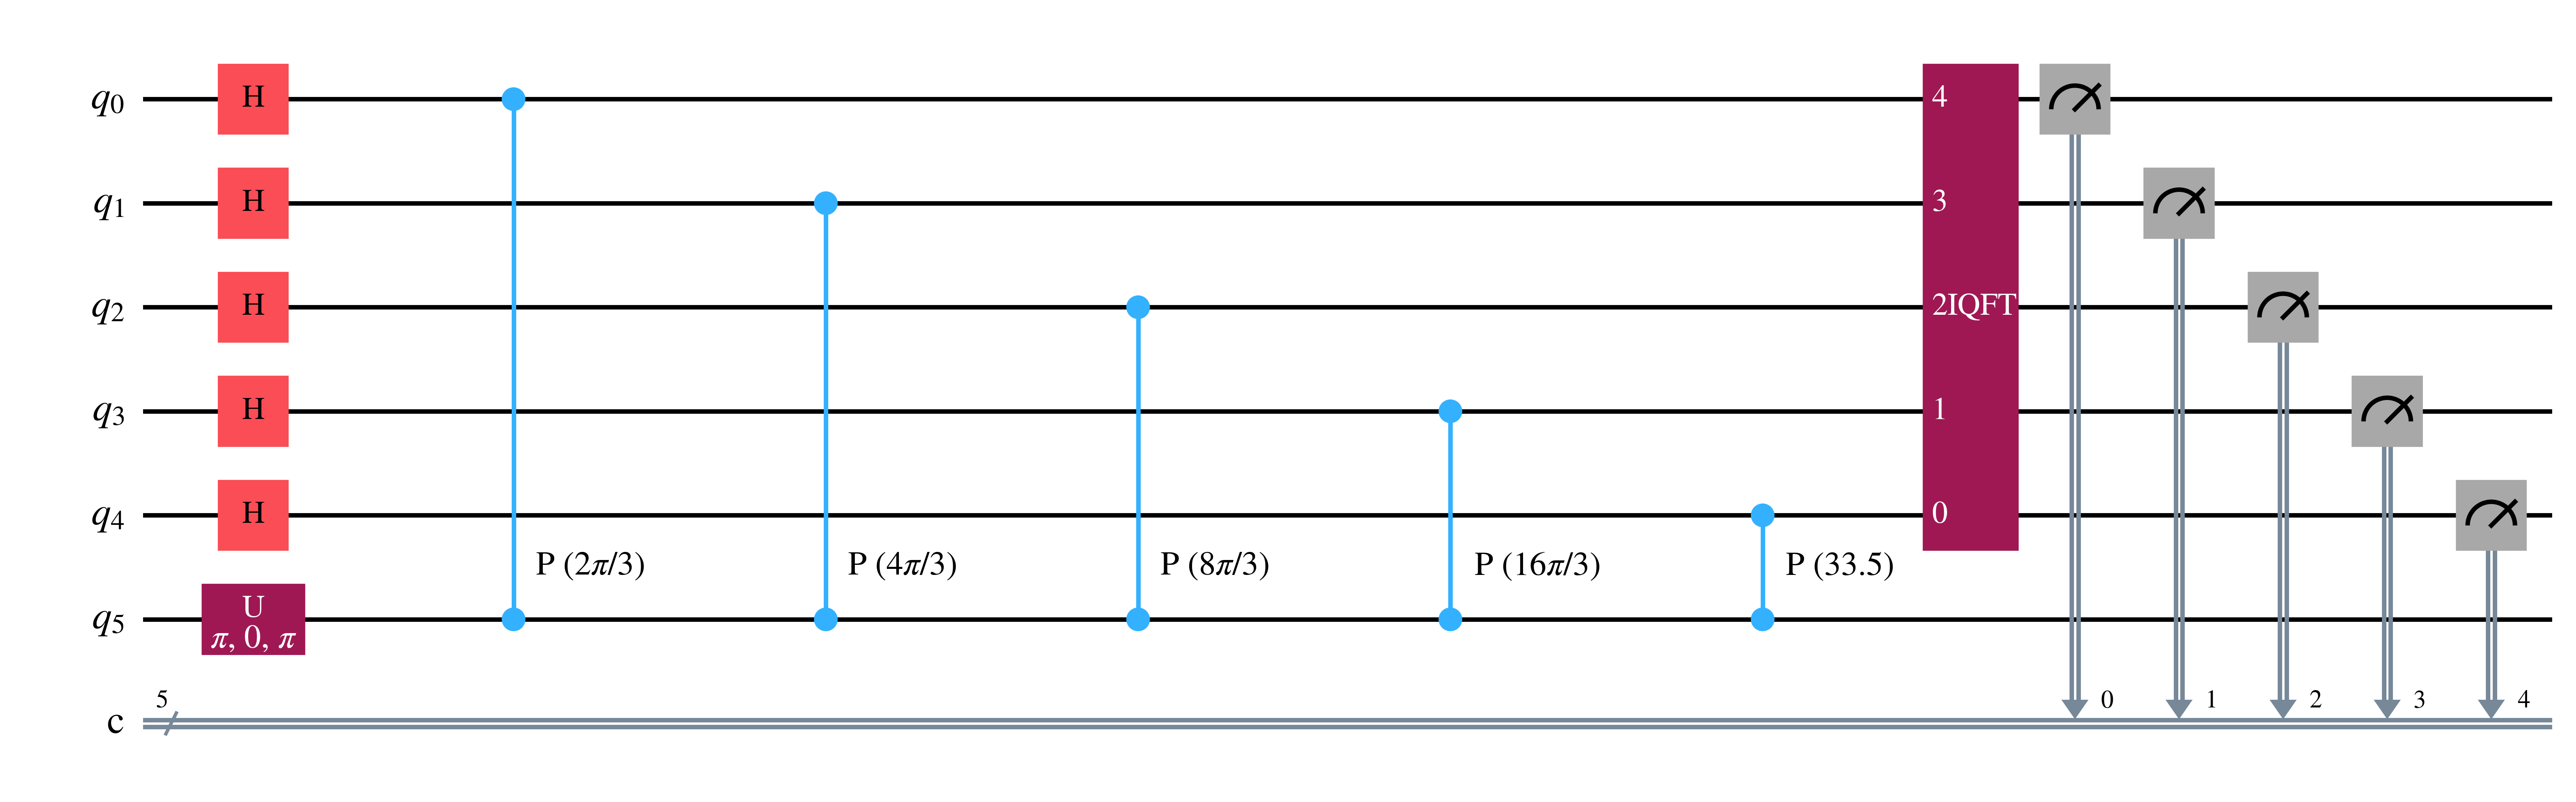

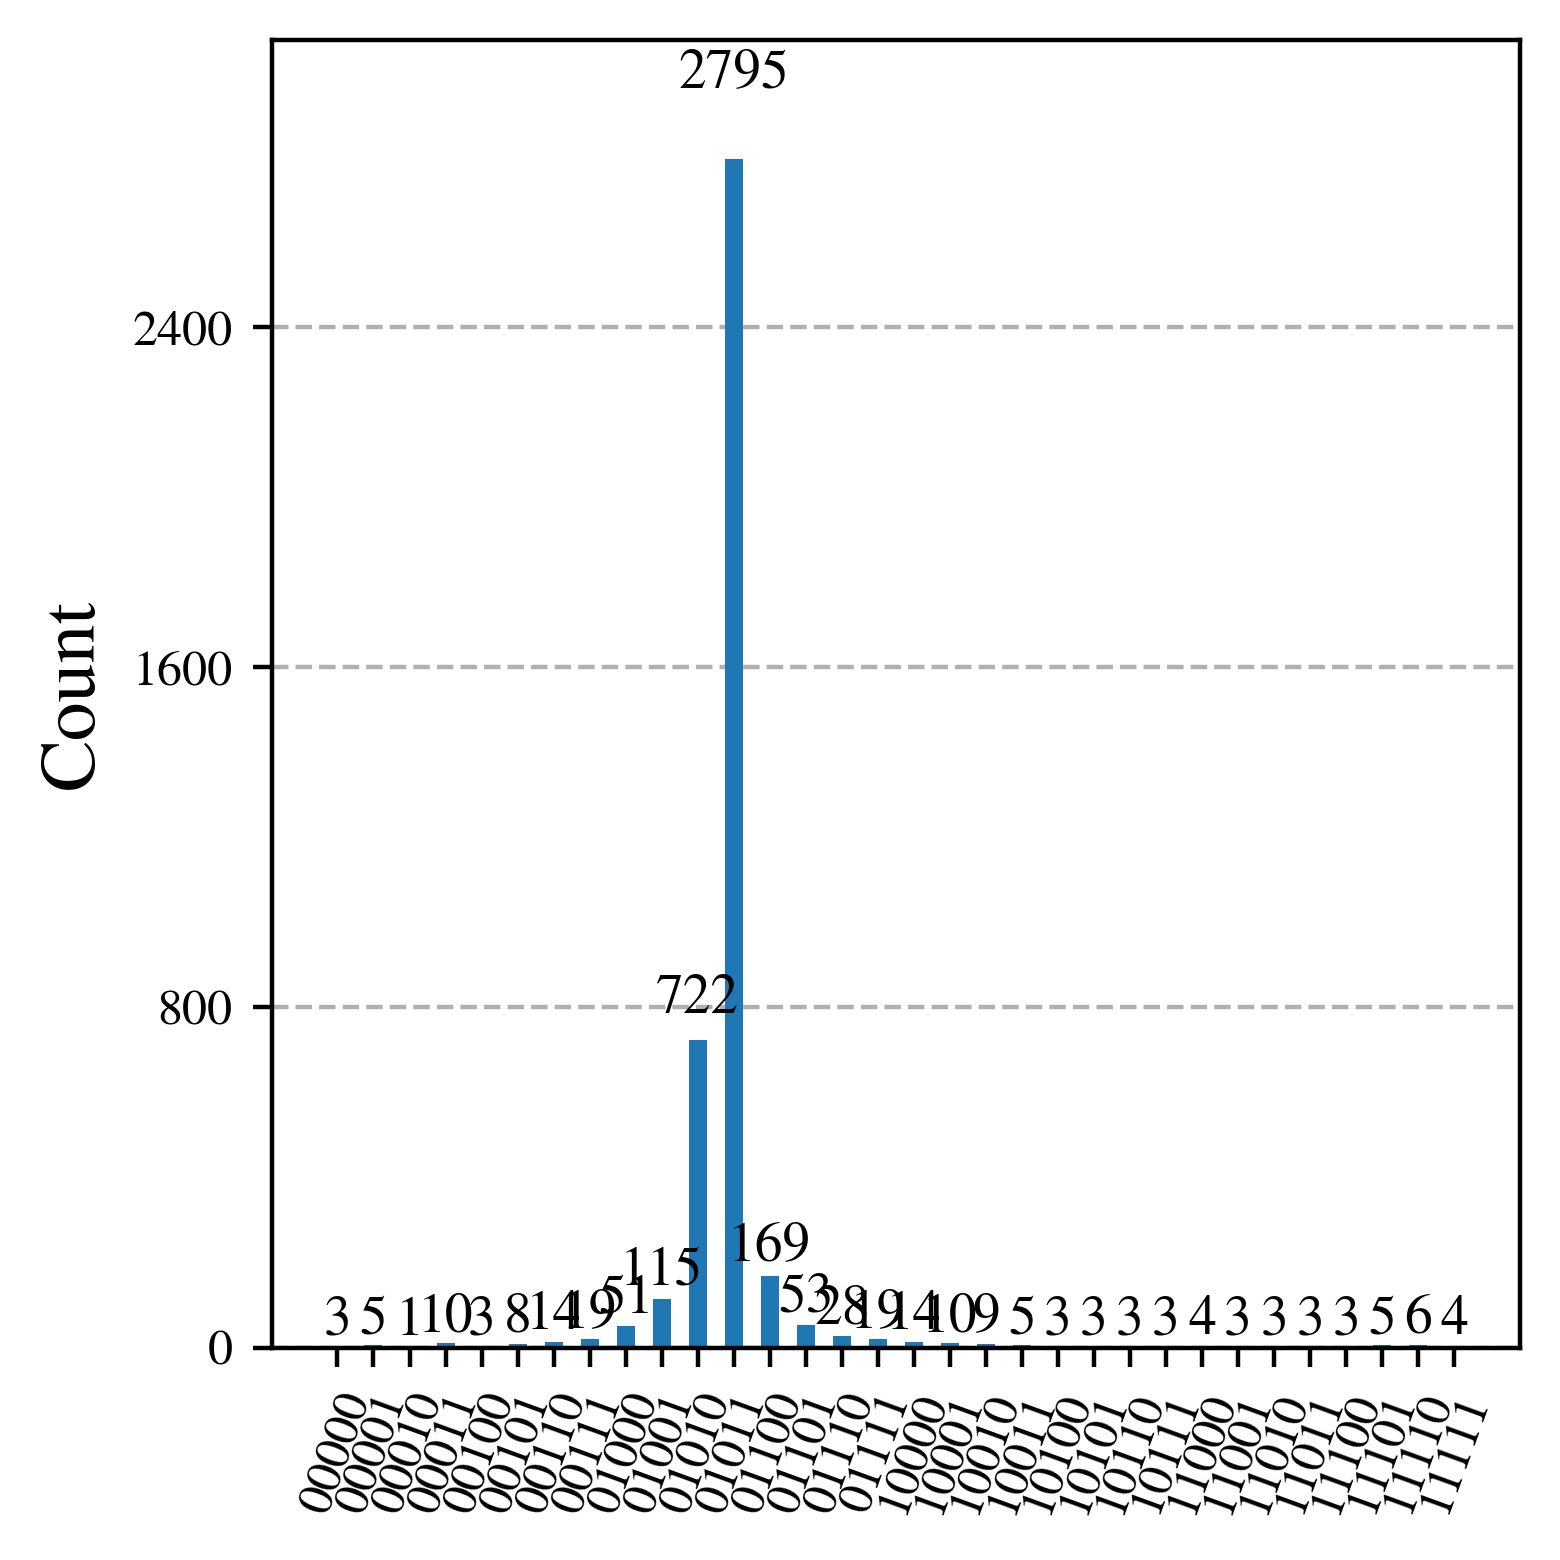

In [5]:
measurement_qubits = 5
qpe = QuantumCircuit(measurement_qubits+1, measurement_qubits)
qpe.x(measurement_qubits)
qpe.compose(PhaseEstimation(measurement_qubits, unitary_p_gate), inplace=True)
for n in range(0,measurement_qubits):
    qpe.measure(n, n)
fig = qpe.decompose().draw("mpl", style=qiskit_style)

aer_sim = AerSimulator()
shots = 4096

pm = generate_preset_pass_manager(backend=aer_sim, optimization_level=1)
t_qpe = pm.run(qpe)

sampler = Sampler(mode=aer_sim)
job = sampler.run([t_qpe], shots=shots)
result = job.result()
answer = result[0].data.c.get_counts()

fig=plot_histogram_reversed(answer)
fig.show()


processed_counts = {}
for bitstring, count in answer.items():
    reversed_bits = bitstring[::-1] 
    
    # Top 3 bits
    n_bits = reversed_bits[:3]
    # First buffer bit (determines if we round up)
    rounding_bit = reversed_bits[3]
    
    if rounding_bit == '1':
        # Round up
        val = (int(n_bits, 2) + 1) % 8
        n_bits = format(val, '03b')
        
    processed_counts[n_bits] = processed_counts.get(n_bits, 0) + count

probability_5_qubits = (processed_counts.get('011', 0) / shots) * 100
output_string = f"Probability of achieving 011 (after rounding) for {measurement_qubits} measurement qubits is {probability_5_qubits:.2f}%"
print(output_string)

The most common result above is 01011, corresponding to $0.01011 = \frac{0}{2^2} + \frac{1}{2^2}+ \frac{0}{2^3} + \frac{1}{2^4} + \frac{1}{2^5} = 0 + 0.25 + 0 + 0.0625 + 0.03125 = 0.34375$.
The second most common result is 01010, corresponding to $0.01010 = \frac{0}{2^2} + \frac{1}{2^2}+ \frac{0}{2^3} + \frac{1}{2^4} + \frac{1}{2^5} = 0 + 0.25 + 0 + 0.0625 + 0 = 0.3125$.

These together bound the expected value of $\frac{1}{3} = 0.33333\ldots = 0.\overline{3}$, and are closer to it than the previous case with three measurement qubits

In [6]:
increase_in_accuracy = probability_5_qubits - probability_3_qubits
print(f"Difference of probability of measuring 011 (after rounding) with 3 and 5 measurement qubits is {increase_in_accuracy:.2f}%")

Difference of probability of measuring 011 (after rounding) with 3 and 5 measurement qubits is 22.05%


Another interesting thing we see as we increase the measurement qubits is an increase in probability of measuring '011' (the closest value to $\frac{1}{3}$) for the first three measurement qubits.
For the 5 qubit state this is measured by rounding the 4th qubit, so a state like '01110' rounds to '012' and a state like '01100' rounds to '011'